# 07 — Voxelwise Kinetic Model Fitting

This notebook fits DCE-MRI pharmacokinetic models to every voxel in a masked
volume using chunked parallel processing.

Each voxel is fit independently via LHS coarse search + TRF refinement.
Results are returned as 3-D spatial parameter maps.

**Contents**
1. Setup and data loading
2. ROI / mask inspection
3. AIF inspection
4. Single test-voxel fit — sanity check before running the full volume
5. Voxelwise fitting — standard mode (TCXM)
6. Inspect parameter maps
7. Save NIfTI maps
8. (Optional) Delay-grid mode
9. (Optional) Continuous-delay mode

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from dce_mri.config import (
    AcquisitionConfig, SubjectConfig,
    FittingConfig, VoxelwiseConfig, FitModeConfig,
    AifConfig,
)
from dce_mri.kinetic_models import TCXM, GKM
from dce_mri.signal_models import (
    signal_to_concentration, concentration_to_signal,
    shift_aif, extract_aif,
)
from dce_mri.fitting import fit_single_voxel
from dce_mri.volume import (
    run_voxelwise_fitting,
    save_nifti_maps,
    load_nifti_canonical,
)

%matplotlib inline
plt.rcParams['figure.dpi'] = 120

## 1. Setup and data loading

In [28]:
# ──: change parameters ──────────

acq     = AcquisitionConfig(TR=4.87, FA=10.0, r1=3.8, nbase=slice(0, 9))
subject = SubjectConfig("test", T10=1530.0, B1=1.0)
cfg     = FittingConfig(n_lhs=200, n_top=10, fit_space="signal")
spokes_per_frame = 34

# ──: load real data ─────────────
#  edit these paths for each subject/dataset
from dce_mri.io import load_aif

DCE_PATH  = "/home/allisonchen/demo_dce_recon/FMB172ROI_3/Img/8spf/FMB172_Basis8_4_8spf_240.nii.gz"
AIF_PATH  = "/home/allisonchen/demo_dce_recon/FMB172ROI_3/ROI/aorta-Case172.nii"
MASK_PATH = "/home/allisonchen/demo_dce_recon/FMB172ROI_3/ROI/malignancy-Case172.nii"


subject = SubjectConfig(
    subject_id        = "FMB172",
    T10               = 1530.0,
    B1                = 1.0,
    dce_path_override  = DCE_PATH,
    aif_path_override  = AIF_PATH,
    mask_path_override = MASK_PATH,
)

sig_4d, ref_img = load_nifti_canonical(subject.dce_path)

# Time parameters
nspoke   = 288     # total spokes across the whole scan
scantime = 150     # total scan duration, seconds

dt = scantime * spokes_per_frame / nspoke
t  = np.arange(sig_4d.shape[-1]) * dt

# load masks
mask_aif, _  = load_nifti_canonical(subject.aif_path)
aif_ROI      = mask_aif.astype(bool)
mask_data, _ = load_nifti_canonical(subject.mask_path)
lesion_ROI   = mask_data.astype(bool)

print(f"Volume shape : {sig_4d.shape}")
print(f"Lesion voxels: {lesion_ROI.sum()}")
print(f"AIF voxels   : {aif_ROI.sum()}")
print(f"Time points  : {len(t)},  dt = {dt:.2f} s")

Volume shape : (320, 320, 192, 36)
Lesion voxels: 335
AIF voxels   : 179
Time points  : 36,  dt = 17.71 s


## 2. Mask inspection

In [29]:
import numpy as np

# z-indices where mask contains at least one voxel
aif_slices = np.where(np.any(aif_ROI, axis=(0, 1)))[0]
lesion_slices = np.where(np.any(lesion_ROI, axis=(0, 1)))[0]

print("AIF slices:", aif_slices)
print("Lesion slices:", lesion_slices)

AIF slices: [82]
Lesion slices: [76 77 78 79 80 81 82 83]


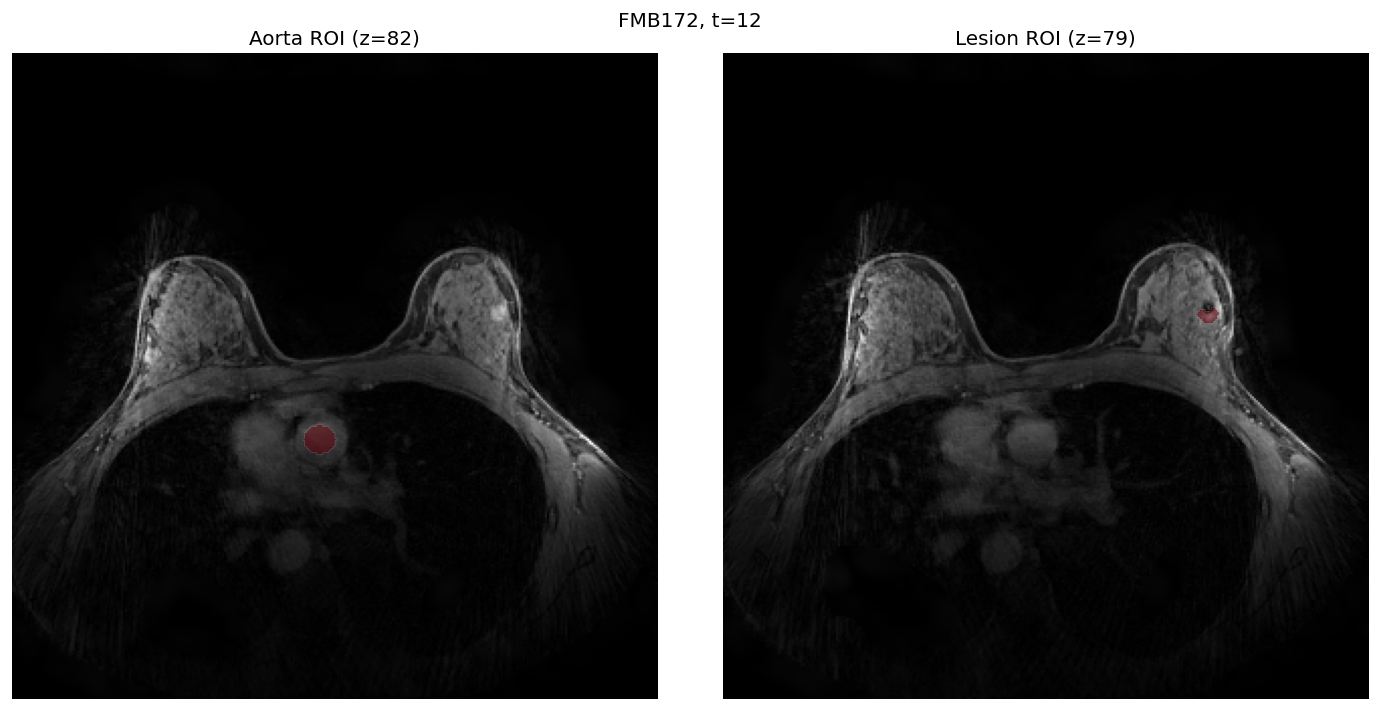

In [30]:
# ──: adjust slice indices to centre on your ROI ──────────
aif_idx    = 82
lesion_idx = 79
time_idx   = 12

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

img_aif    = sig_4d[:, :, aif_idx,    time_idx]
img_lesion = sig_4d[:, :, lesion_idx, time_idx]

axes[0].imshow(img_aif.T,    cmap="gray", origin="lower")
axes[0].imshow(aif_ROI[:, :, aif_idx].T,
               cmap="Reds", alpha=0.5 * aif_ROI[:, :, aif_idx].T, origin="lower")
axes[0].set_title(f"Aorta ROI (z={aif_idx})")
axes[0].axis("off")

axes[1].imshow(img_lesion.T, cmap="gray", origin="lower")
axes[1].imshow(lesion_ROI[:, :, lesion_idx].T,
               cmap="Reds", alpha=0.5 * lesion_ROI[:, :, lesion_idx].T, origin="lower")
axes[1].set_title(f"Lesion ROI (z={lesion_idx})")
axes[1].axis("off")

plt.suptitle(f"{subject.subject_id}, t={time_idx}")
plt.tight_layout()
plt.show()

## 3. AIF inspection

AIF signal range : [14.7, 72.4]
AIF plasma range : [-0.0450, 2.9880] mM
AIF peak time    : 407.3 s
AIF peak value   : 2.9880 mM


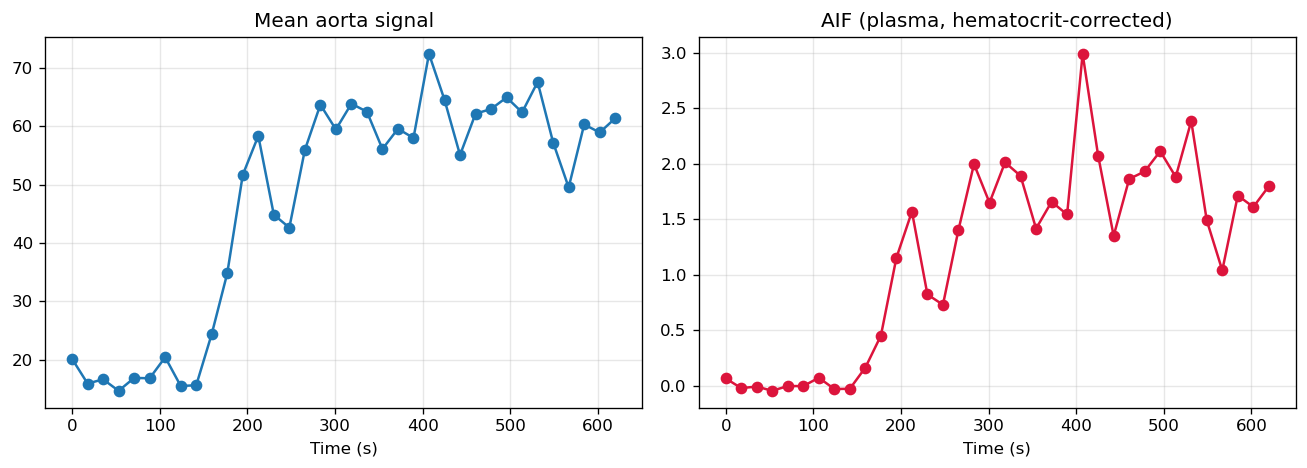

In [31]:
aif_cfg = AifConfig(
    T10        = 1664.0,
    hematocrit = 0.45,
    top_frac   = 1.0,
    nbase      = acq.nbase,
)

aif, aif_signal = extract_aif(sig_4d, aif_ROI, acq, aif_cfg, B1=subject.B1)

print(f"AIF signal range : [{aif_signal.min():.1f}, {aif_signal.max():.1f}]")
print(f"AIF plasma range : [{aif.min():.4f}, {aif.max():.4f}] mM")
print(f"AIF peak time    : {t[np.argmax(aif)]:.1f} s")
print(f"AIF peak value   : {aif.max():.4f} mM")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(t, aif_signal, 'o-')
axes[0].set_title("Mean aorta signal")
axes[0].set_xlabel("Time (s)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(t, aif, 'o-', color='crimson')
axes[1].set_title("AIF (plasma, hematocrit-corrected)")
axes[1].set_xlabel("Time (s)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Single test-voxel fit

Fit one voxel by hand before committing to the full volume run.
This is the fastest way to catch config errors and check that the
signal curves look reasonable.

Pick a voxel near the centre of the lesion mask.

Test voxel: (240, 189, 76)


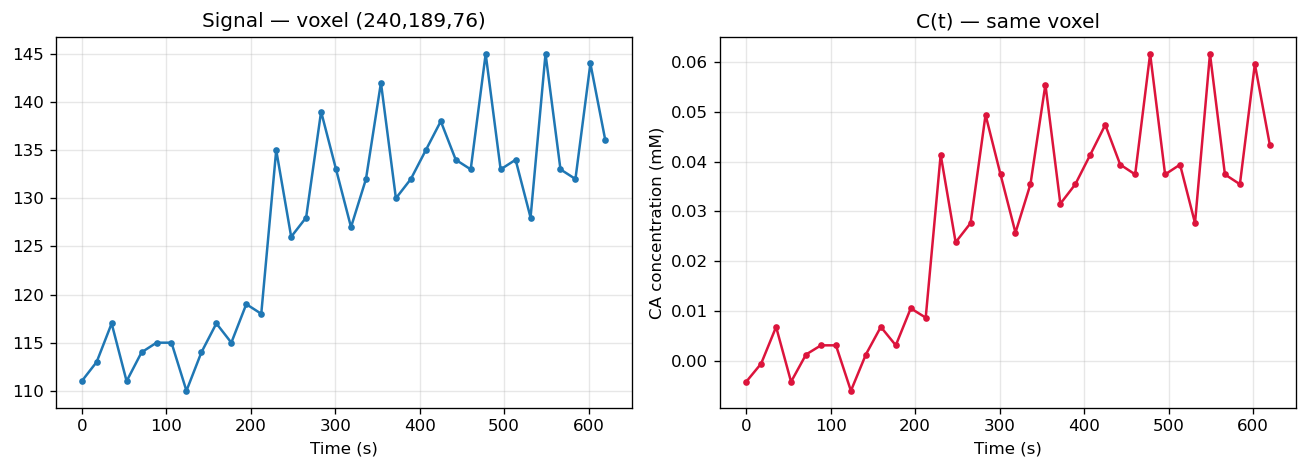

In [32]:
# find the centroid of the lesion mask and use it as the test voxel
coords = np.argwhere(lesion_ROI)
i0, j0, k0 = coords[len(coords) // 2]   # median voxel
print(f"Test voxel: ({i0}, {j0}, {k0})")

sig_v = sig_4d[i0, j0, k0, :]
Ct_v  = signal_to_concentration(sig_v, acq, subject.T10, subject.B1)

# quick visual check of the test voxel curves
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t, sig_v, 'o-', ms=3)
axes[0].set_title(f"Signal — voxel ({i0},{j0},{k0})")
axes[0].set_xlabel("Time (s)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(t, Ct_v, 'o-', ms=3, color='crimson')
axes[1].set_title("C(t) — same voxel")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("CA concentration (mM)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

success : True
cost    : 8.2514e+02
  ve      : 0.02326
  vp      : 0.00010
  fp      : 0.00167
  ps      : 0.00114


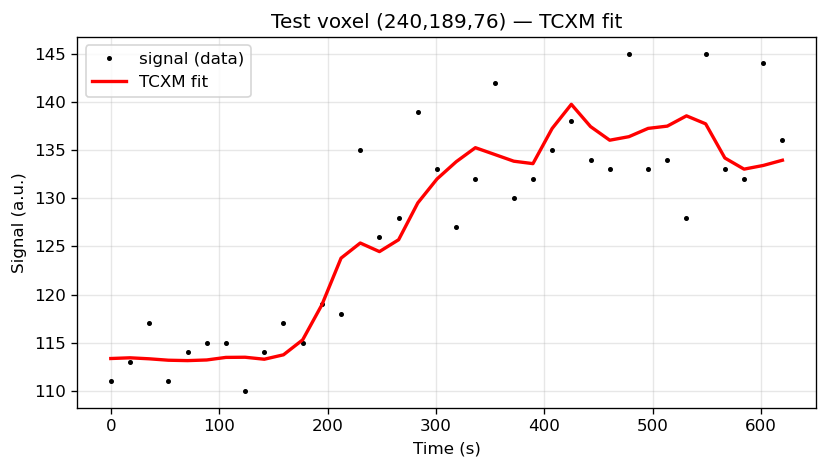

In [33]:
# fit TCXM to the test voxel
result_test = fit_single_voxel(sig_v, aif, t, TCXM, acq, subject, cfg, seed=0)

print(f"success : {result_test.success}")
print(f"cost    : {result_test.cost:.4e}")
for name, val in zip(TCXM.param_names, result_test.params):
    print(f"  {name:8s}: {val:.5f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t, result_test.S_meas, 'k.', ms=4, label='signal (data)')
ax.plot(t, result_test.S_pred, 'r-', lw=2, label='TCXM fit')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Signal (a.u.)')
ax.set_title(f'Test voxel ({i0},{j0},{k0}) — TCXM fit')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Voxelwise fitting — standard mode

`chunk_size` controls the number of voxels per worker task.
Typical starting points:
- small lesion  (< 500 voxels) : chunk_size = 50
- medium lesion (500 – 5 000)  : chunk_size = 200
- large volume  (> 5 000)      : chunk_size = 500

In [34]:
vox_cfg  = VoxelwiseConfig(
    n_workers     = 24,        # adjust to your CPU count
    chunk_size    = 20,
    save_dir      = f"/tmp/{subject.subject_id}_maps",
    output_prefix = "tcxm_",
)
mode_cfg = FitModeConfig(mode="standard")

result = run_voxelwise_fitting(
    sig_4d, aif, t, TCXM,
    acq, subject, cfg, vox_cfg, lesion_ROI, mode_cfg,
)

print(f"n_voxels : {result.n_voxels}")
print(f"n_success: {result.n_success}  ({100*result.n_success/result.n_voxels:.1f}%)")
print(f"elapsed  : {result.elapsed_s:.1f} s")

[volume] fitting 335 voxels (16 chunks, 24 workers, chunk_size=20) ...
[volume] done — 335/335 successful in 258.1s
n_voxels : 335
n_success: 335  (100.0%)
elapsed  : 258.1 s


## 6. Inspect parameter maps

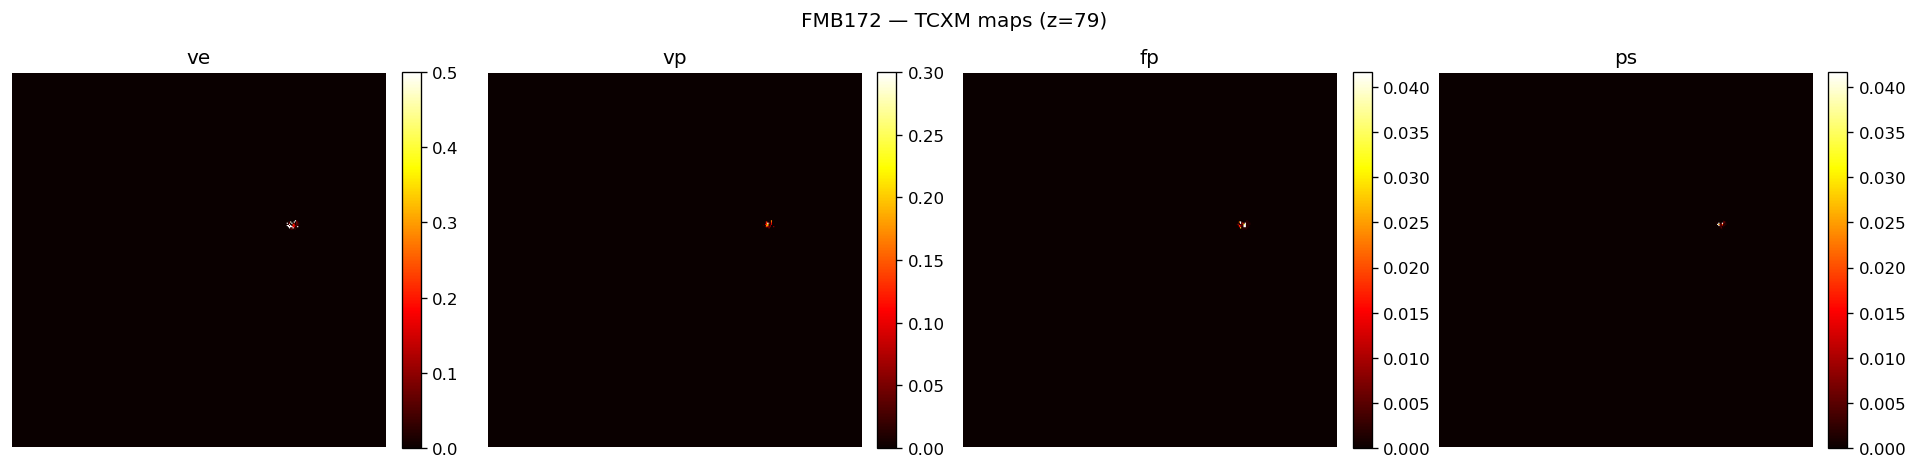

In [35]:
# show all four TCXM parameter maps on the lesion slice
param_display = {
    've':  (0.0,  0.5),
    'vp':  (0.0,  0.3),
    'fp':  (0.0,  2.5/60),
    'ps':  (0.0,  2.5/60),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (name, (vmin, vmax)) in zip(axes, param_display.items()):
    img = result.param_maps[name][:, :, lesion_idx]
    im  = ax.imshow(img.T, cmap='hot', origin='lower', vmin=vmin, vmax=vmax)
    ax.set_title(name)
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(f"{subject.subject_id} — TCXM maps (z={lesion_idx})")
plt.tight_layout()
plt.show()

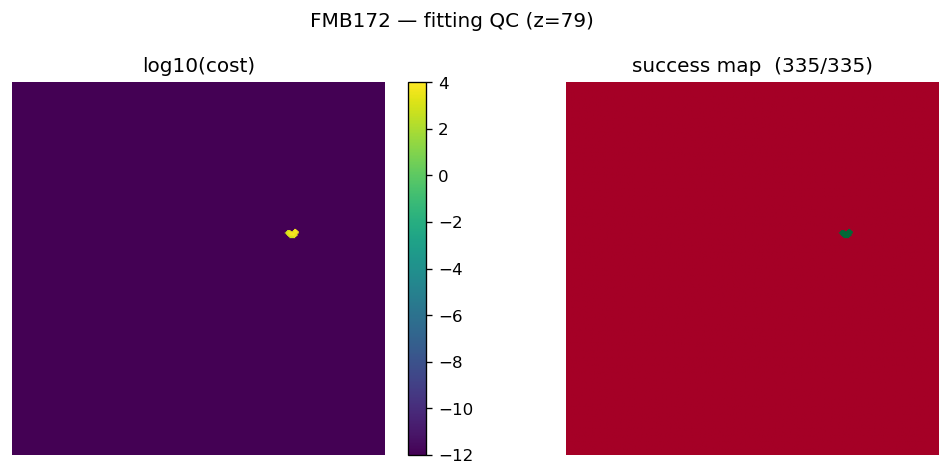

In [36]:
# cost and success maps
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im0 = axes[0].imshow(
    np.log10(result.cost_map[:, :, lesion_idx].T + 1e-12),
    cmap='viridis', origin='lower'
)
axes[0].set_title('log10(cost)')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].imshow(result.success_map[:, :, lesion_idx].T,
               cmap='RdYlGn', origin='lower', vmin=0, vmax=1)
axes[1].set_title(f'success map  ({result.n_success}/{result.n_voxels})')
axes[1].axis('off')

plt.suptitle(f"{subject.subject_id} — fitting QC (z={lesion_idx})")
plt.tight_layout()
plt.show()

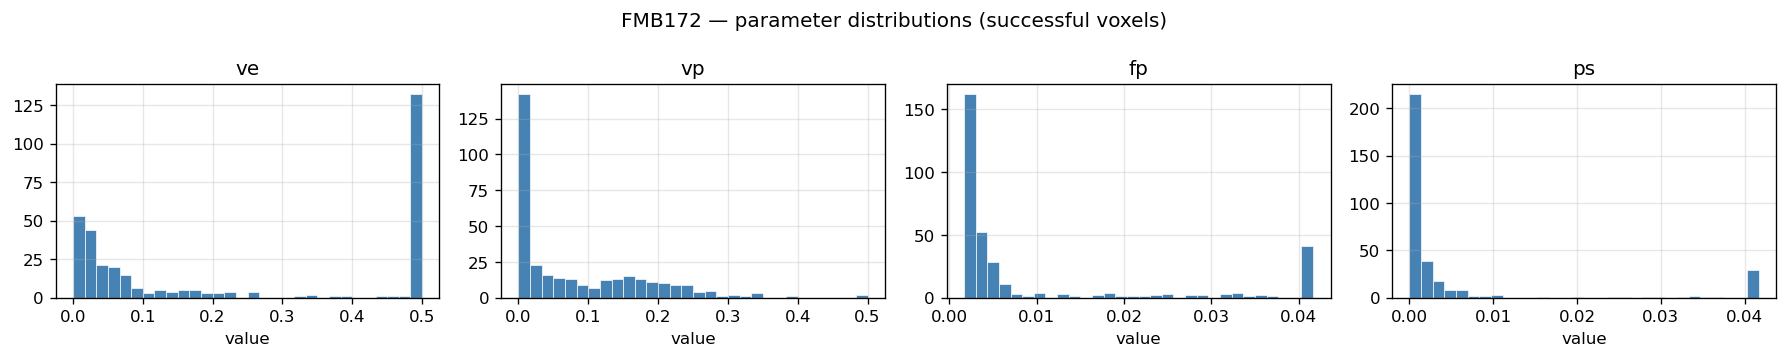

ve    : median=0.13347  iqr=[0.02946, 0.49999]
vp    : median=0.03457  iqr=[0.00015, 0.15182]
fp    : median=0.00313  iqr=[0.00167, 0.00654]
ps    : median=0.00033  iqr=[0.00003, 0.00262]


In [37]:
# parameter distributions — successful voxels only
success_flat = result.success_map[lesion_ROI]

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, name in zip(axes, TCXM.param_names):
    vals = result.param_maps[name][lesion_ROI][success_flat]
    ax.hist(vals, bins=30, color='steelblue', edgecolor='white', linewidth=0.4)
    ax.set_title(name)
    ax.set_xlabel('value')
    ax.grid(True, alpha=0.3)

plt.suptitle(f"{subject.subject_id} — parameter distributions (successful voxels)")
plt.tight_layout()
plt.show()

for name in TCXM.param_names:
    vals = result.param_maps[name][lesion_ROI][success_flat]
    print(f"{name:6s}: median={np.median(vals):.5f}  iqr=[{np.percentile(vals,25):.5f}, {np.percentile(vals,75):.5f}]")

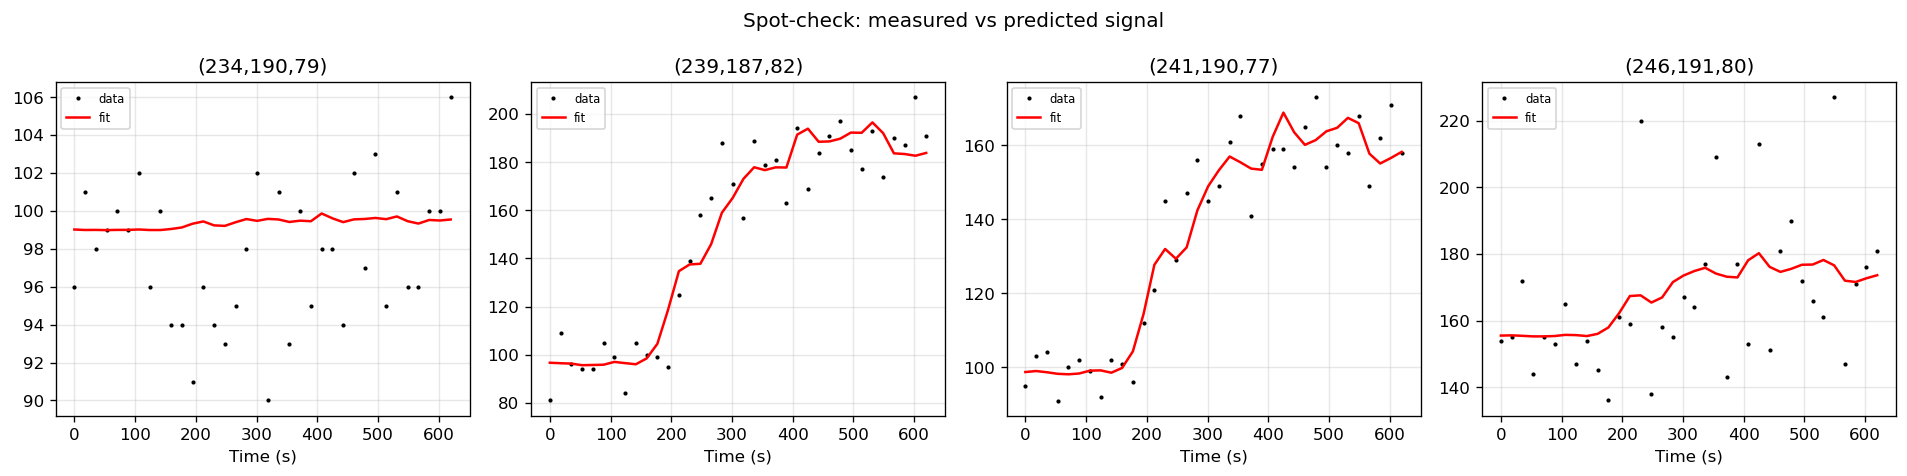

In [38]:
# spot-check: overlay predicted vs measured for a few successful voxels
success_coords = np.argwhere(result.success_map & lesion_ROI)
n_show = min(4, len(success_coords))
chosen = success_coords[np.linspace(0, len(success_coords)-1, n_show, dtype=int)]

fig, axes = plt.subplots(1, n_show, figsize=(4*n_show, 4))
if n_show == 1:
    axes = [axes]

for ax, (i, j, k) in zip(axes, chosen):
    sig_v  = sig_4d[i, j, k, :]
    params = np.array([result.param_maps[n][i,j,k] for n in TCXM.param_names])
    from dce_mri.signal_models import compute_S0
    S0     = float(compute_S0(sig_v[None, :], acq)[0])
    Ct_p   = TCXM.fn(params, t, aif)
    S_pred = concentration_to_signal(Ct_p, acq, subject.T10, subject.B1, S0)

    ax.plot(t, sig_v,  'k.', ms=3, label='data')
    ax.plot(t, S_pred, 'r-', lw=1.5, label='fit')
    ax.set_title(f"({i},{j},{k})")
    ax.set_xlabel('Time (s)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

plt.suptitle('Spot-check: measured vs predicted signal')
plt.tight_layout()
plt.show()

## 7. Save NIfTI maps

In [39]:
save_nifti_maps(result, ref_img, vox_cfg)
print("Saved to:", vox_cfg.save_dir)

[volume] saved /tmp/FMB172_maps/tcxm_ve.nii.gz
[volume] saved /tmp/FMB172_maps/tcxm_vp.nii.gz
[volume] saved /tmp/FMB172_maps/tcxm_fp.nii.gz
[volume] saved /tmp/FMB172_maps/tcxm_ps.nii.gz
[volume] saved /tmp/FMB172_maps/tcxm_cost.nii.gz
[volume] saved /tmp/FMB172_maps/tcxm_success.nii.gz
Saved to: /tmp/FMB172_maps


## 8. (Optional) Delay-grid mode

Fits the kinetic model at each tau in a discrete grid and picks the best.
Useful when you expect consistent AIF delays across the lesion.

tau grid: [-10.   0.  10.  20.  30.  40.  50.  60.  70.  80.  90. 100. 110. 120.
 130. 140. 150. 160. 170. 180. 190.] s
[volume] fitting 335 voxels (16 chunks, 24 workers, chunk_size=20) ...
[volume] done — 335/335 successful in 645.8s
n_success: 335/335


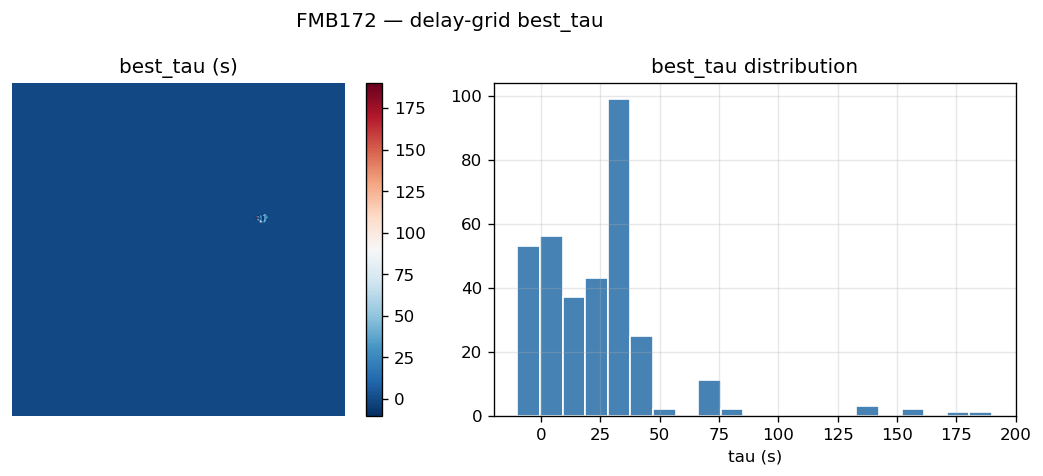

In [40]:
tau_values = np.arange(-10.0, 200.0, 10.0)   # 9 values
print(f"tau grid: {tau_values} s")

mode_cfg_grid = FitModeConfig(
    mode          = "delay_grid",
    tau_values    = tau_values,
    interp_method = "pchip",
)

vox_cfg_grid = VoxelwiseConfig(
    n_workers     = 24,
    chunk_size    = 20,
    save_dir      = f"/tmp/{subject.subject_id}_maps_delay_grid",
    output_prefix = "tcxm_delay_grid_",
)

result_grid = run_voxelwise_fitting(
    sig_4d, aif, t, TCXM,
    acq, subject, cfg, vox_cfg_grid, lesion_ROI, mode_cfg_grid,
)

print(f"n_success: {result_grid.n_success}/{result_grid.n_voxels}")

# best_tau map
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im0 = axes[0].imshow(result_grid.param_maps['best_tau'][:, :, lesion_idx].T,
                     cmap='RdBu_r', origin='lower')
axes[0].set_title('best_tau (s)')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].hist(result_grid.param_maps['best_tau'][lesion_ROI], bins=len(tau_values),
             color='steelblue', edgecolor='white')
axes[1].set_title('best_tau distribution')
axes[1].set_xlabel('tau (s)')
axes[1].grid(True, alpha=0.3)

plt.suptitle(f"{subject.subject_id} — delay-grid best_tau")
plt.tight_layout()
plt.show()

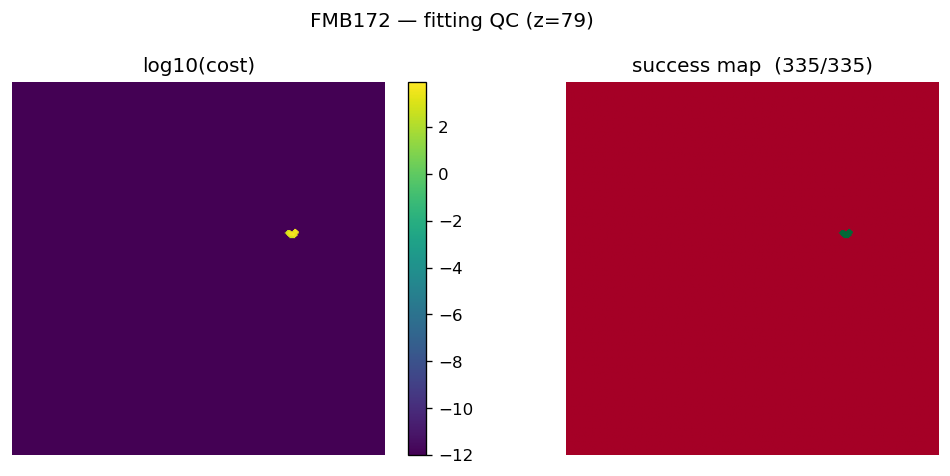

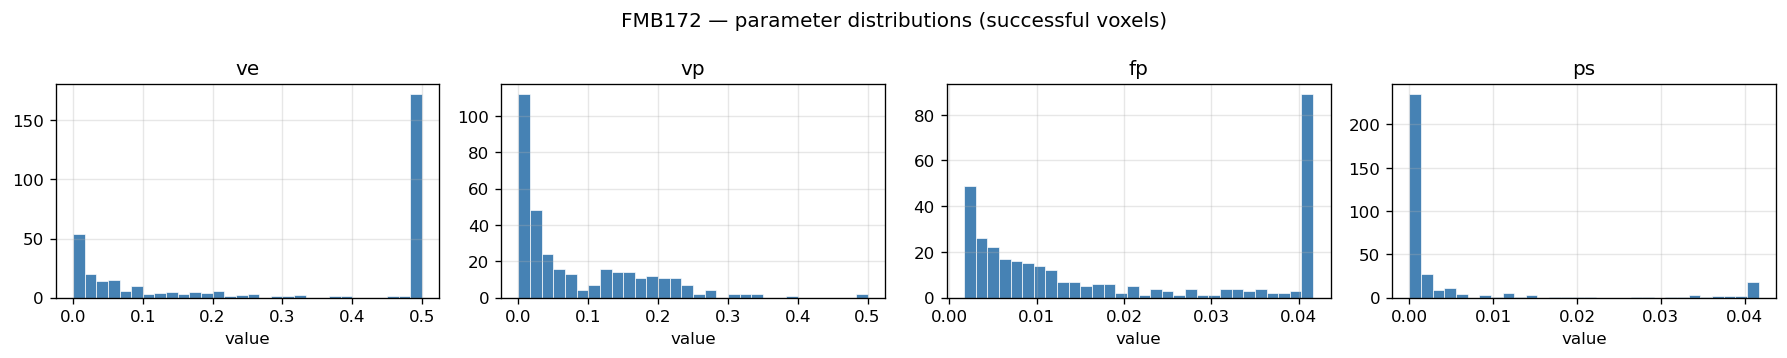

ve    : median=0.49877  iqr=[0.04509, 0.50000]
vp    : median=0.03908  iqr=[0.00941, 0.14659]
fp    : median=0.01179  iqr=[0.00495, 0.04166]
ps    : median=0.00007  iqr=[0.00001, 0.00206]


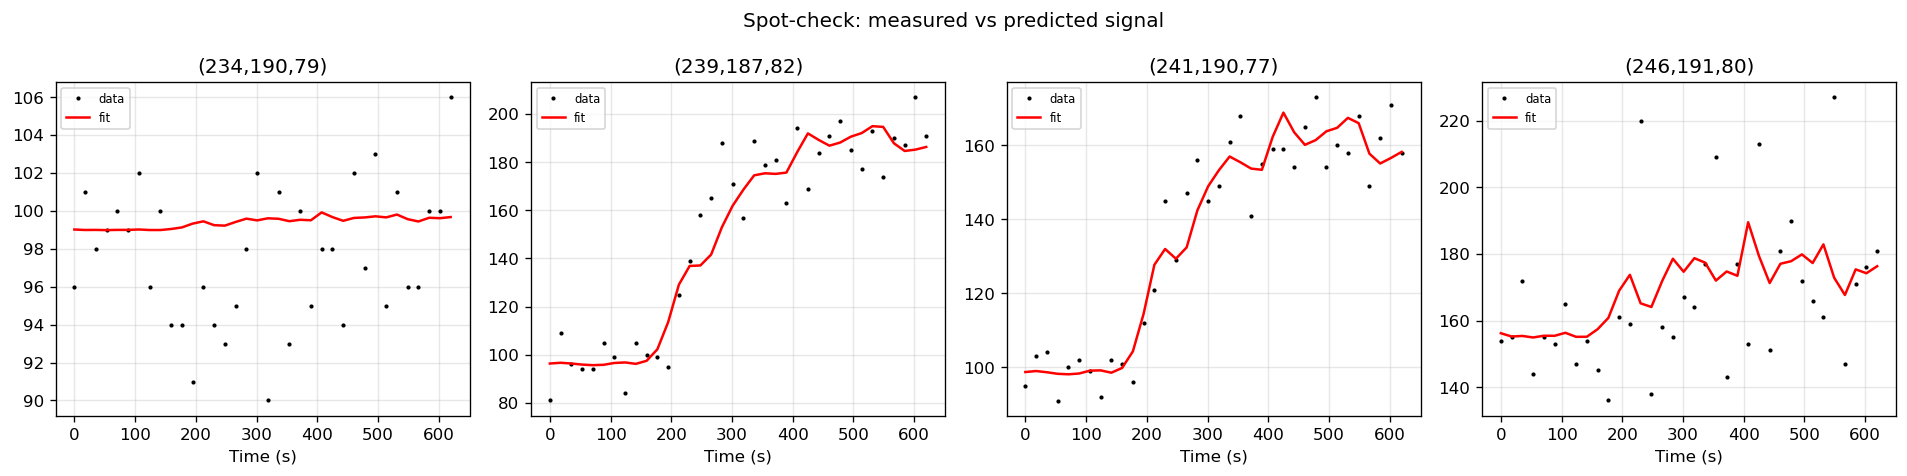

In [41]:
# parameter distributions — successful voxels only
# cost and success maps
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im0 = axes[0].imshow(
    np.log10(result_grid.cost_map[:, :, lesion_idx].T + 1e-12),
    cmap='viridis', origin='lower'
)
axes[0].set_title('log10(cost)')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].imshow(result_grid.success_map[:, :, lesion_idx].T,
               cmap='RdYlGn', origin='lower', vmin=0, vmax=1)
axes[1].set_title(f'success map  ({result.n_success}/{result.n_voxels})')
axes[1].axis('off')

plt.suptitle(f"{subject.subject_id} — fitting QC (z={lesion_idx})")
plt.tight_layout()
plt.show()
success_flat = result_grid.success_map[lesion_ROI]

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, name in zip(axes, TCXM.param_names):
    vals = result_grid.param_maps[name][lesion_ROI][success_flat]
    ax.hist(vals, bins=30, color='steelblue', edgecolor='white', linewidth=0.4)
    ax.set_title(name)
    ax.set_xlabel('value')
    ax.grid(True, alpha=0.3)

plt.suptitle(f"{subject.subject_id} — parameter distributions (successful voxels)")
plt.tight_layout()
plt.show()

for name in TCXM.param_names:
    vals = result_grid.param_maps[name][lesion_ROI][success_flat]
    print(f"{name:6s}: median={np.median(vals):.5f}  iqr=[{np.percentile(vals,25):.5f}, {np.percentile(vals,75):.5f}]")
# spot-check: overlay predicted vs measured for a few successful voxels
success_coords = np.argwhere(result_grid.success_map & lesion_ROI)
n_show = min(4, len(success_coords))
chosen = success_coords[np.linspace(0, len(success_coords)-1, n_show, dtype=int)]

fig, axes = plt.subplots(1, n_show, figsize=(4*n_show, 4))
if n_show == 1:
    axes = [axes]

for ax, (i, j, k) in zip(axes, chosen):
    sig_v  = sig_4d[i, j, k, :]
    params = np.array([result_grid.param_maps[n][i,j,k] for n in TCXM.param_names])
    from dce_mri.signal_models import compute_S0
    S0     = float(compute_S0(sig_v[None, :], acq)[0])
    Ct_p   = TCXM.fn(params, t, aif)
    S_pred = concentration_to_signal(Ct_p, acq, subject.T10, subject.B1, S0)

    ax.plot(t, sig_v,  'k.', ms=3, label='data')
    ax.plot(t, S_pred, 'r-', lw=1.5, label='fit')
    ax.set_title(f"({i},{j},{k})")
    ax.set_xlabel('Time (s)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

plt.suptitle('Spot-check: measured vs predicted signal')
plt.tight_layout()
plt.show()

## 9. (Optional) Continuous-delay mode

Optimises tau jointly with the kinetic parameters inside LHS + TRF.
Higher quality than grid search but slower.

[volume] fitting 335 voxels (16 chunks, 24 workers, chunk_size=20) ...
[volume] done — 335/335 successful in 325.5s
n_success: 335/335


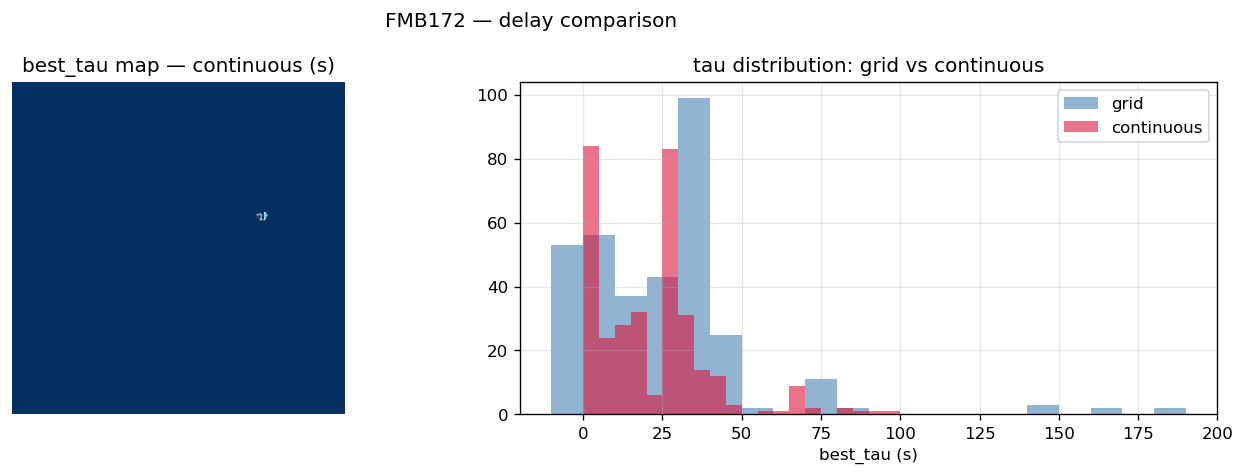

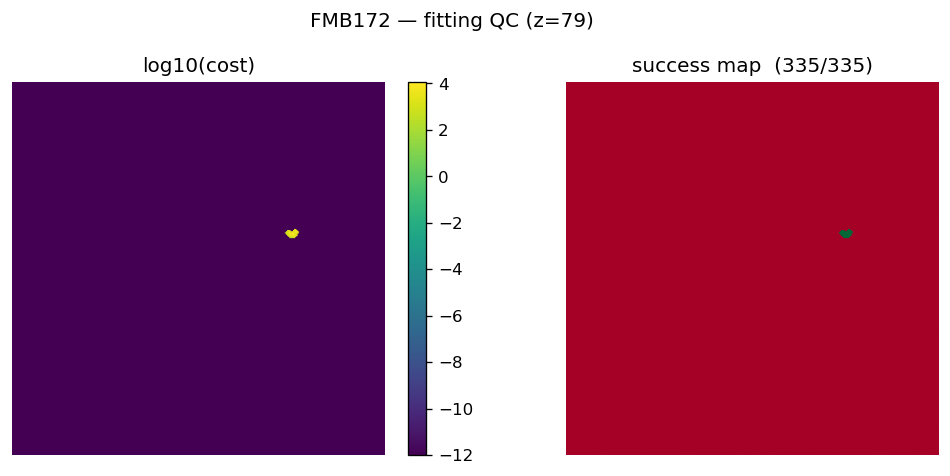

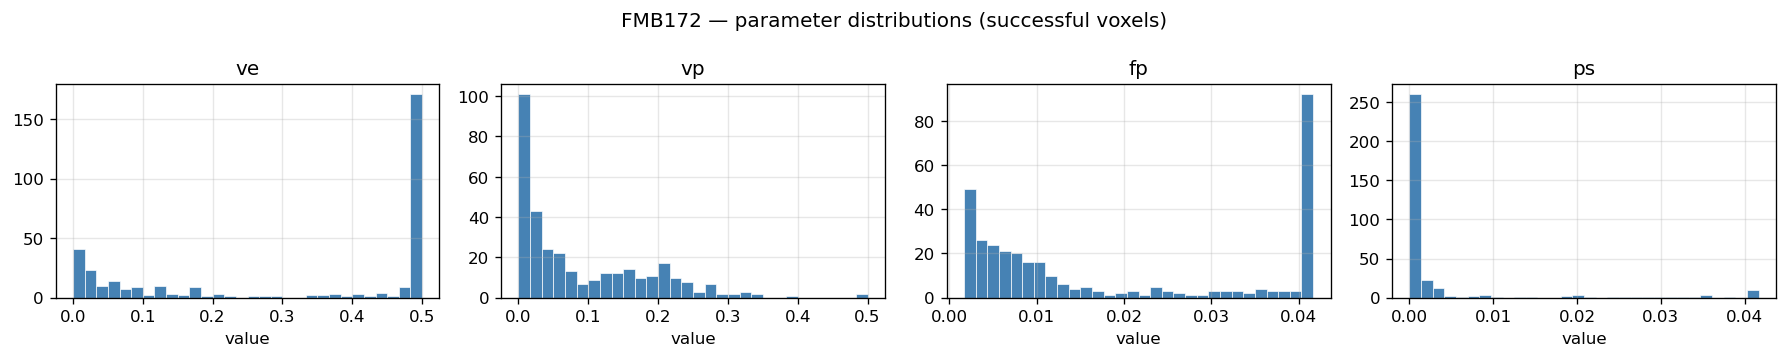

ve    : median=0.48867  iqr=[0.06264, 0.50000]
vp    : median=0.04909  iqr=[0.01172, 0.15821]
fp    : median=0.01024  iqr=[0.00493, 0.04166]
ps    : median=0.00004  iqr=[0.00001, 0.00098]


In [42]:
mode_cfg_cont = FitModeConfig(
    mode          = "delay_continuous",
    tau_lb        = 0.0,
    tau_ub        =  100.0,
    tau_p0        =   25.0,
    interp_method = "pchip",
)

vox_cfg_cont = VoxelwiseConfig(
    n_workers     = 24,
    chunk_size    = 20,
    save_dir      = f"/tmp/{subject.subject_id}_maps_delay_cont",
    output_prefix = "tcxm_delay_cont_",
)

result_cont = run_voxelwise_fitting(
    sig_4d, aif, t, TCXM,
    acq, subject, cfg, vox_cfg_cont, lesion_ROI, mode_cfg_cont,
)

print(f"n_success: {result_cont.n_success}/{result_cont.n_voxels}")

# compare tau distributions: grid vs continuous
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(result_cont.param_maps['best_tau'][:, :, lesion_idx].T,
               cmap='RdBu_r', origin='lower')
axes[0].set_title('best_tau map — continuous (s)')
axes[0].axis('off')

axes[1].hist(result_grid.param_maps['best_tau'][lesion_ROI],
             bins=20, alpha=0.6, label='grid', color='steelblue')
axes[1].hist(result_cont.param_maps['best_tau'][lesion_ROI],
             bins=20, alpha=0.6, label='continuous', color='crimson')
axes[1].set_xlabel('best_tau (s)')
axes[1].set_title('tau distribution: grid vs continuous')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle(f"{subject.subject_id} — delay comparison")
plt.tight_layout()
plt.show()

# parameter distributions — successful voxels only
# cost and success maps
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im0 = axes[0].imshow(
    np.log10(result_cont.cost_map[:, :, lesion_idx].T + 1e-12),
    cmap='viridis', origin='lower'
)
axes[0].set_title('log10(cost)')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].imshow(result_cont.success_map[:, :, lesion_idx].T,
               cmap='RdYlGn', origin='lower', vmin=0, vmax=1)
axes[1].set_title(f'success map  ({result.n_success}/{result.n_voxels})')
axes[1].axis('off')

plt.suptitle(f"{subject.subject_id} — fitting QC (z={lesion_idx})")
plt.tight_layout()
plt.show()
success_flat = result_cont.success_map[lesion_ROI]

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, name in zip(axes, TCXM.param_names):
    vals = result_cont.param_maps[name][lesion_ROI][success_flat]
    ax.hist(vals, bins=30, color='steelblue', edgecolor='white', linewidth=0.4)
    ax.set_title(name)
    ax.set_xlabel('value')
    ax.grid(True, alpha=0.3)

plt.suptitle(f"{subject.subject_id} — parameter distributions (successful voxels)")
plt.tight_layout()
plt.show()

for name in TCXM.param_names:
    vals = result_cont.param_maps[name][lesion_ROI][success_flat]
    print(f"{name:6s}: median={np.median(vals):.5f}  iqr=[{np.percentile(vals,25):.5f}, {np.percentile(vals,75):.5f}]")

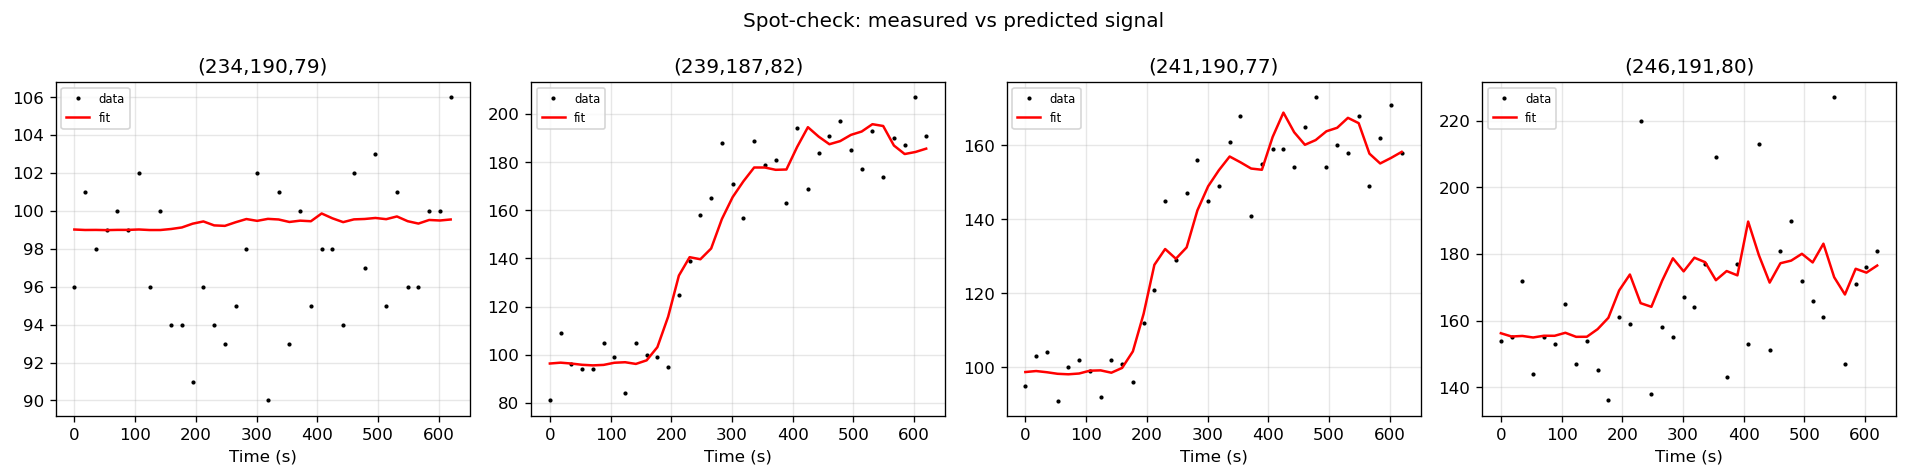

In [43]:
# spot-check: overlay predicted vs measured for a few successful voxels
success_coords = np.argwhere(result_cont.success_map & lesion_ROI)
n_show = min(4, len(success_coords))
chosen = success_coords[np.linspace(0, len(success_coords)-1, n_show, dtype=int)]

fig, axes = plt.subplots(1, n_show, figsize=(4*n_show, 4))
if n_show == 1:
    axes = [axes]

for ax, (i, j, k) in zip(axes, chosen):
    sig_v  = sig_4d[i, j, k, :]
    params = np.array([result_cont.param_maps[n][i,j,k] for n in TCXM.param_names])
    from dce_mri.signal_models import compute_S0
    S0     = float(compute_S0(sig_v[None, :], acq)[0])
    Ct_p   = TCXM.fn(params, t, aif)
    S_pred = concentration_to_signal(Ct_p, acq, subject.T10, subject.B1, S0)

    ax.plot(t, sig_v,  'k.', ms=3, label='data')
    ax.plot(t, S_pred, 'r-', lw=1.5, label='fit')
    ax.set_title(f"({i},{j},{k})")
    ax.set_xlabel('Time (s)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7)

plt.suptitle('Spot-check: measured vs predicted signal')
plt.tight_layout()
plt.show()